# MAE +16 action-advantage persistence gate

**Gate missed.** The action selected at +16 had an estimated semantic gain of **+0.140 pp**
in E244 and **+0.014 pp** in E249 after common continuation, with 95% intervals spanning zero
on independent query captures and mask draws. The three-predictor fit remains gated.

## What was tested

For each source state, select the retrospectively best action at +16 on one query panel
and mask draw. Keep that action fixed and score its branch after 32 more arrivals under
the common reference policy. Compare it with the Skip branch under the same continuation,
using a different mask draw and a capture-disjoint query panel. The relevant row is
**+16 → +48**. A +48 → +48 oracle can select again at the later horizon.

The check reuses the published E244 and E249 branch evaluations. Both use the same 12 source
captures and three independently trained MAE seeds. E249 introduces fresh query pools and
its largest panel has 48 captures per class and side. E244 resamples seeds and source
captures. The largest E249 panel also resamples query captures. These are checks on
evaluation-population transfer for the archived learner trajectories.

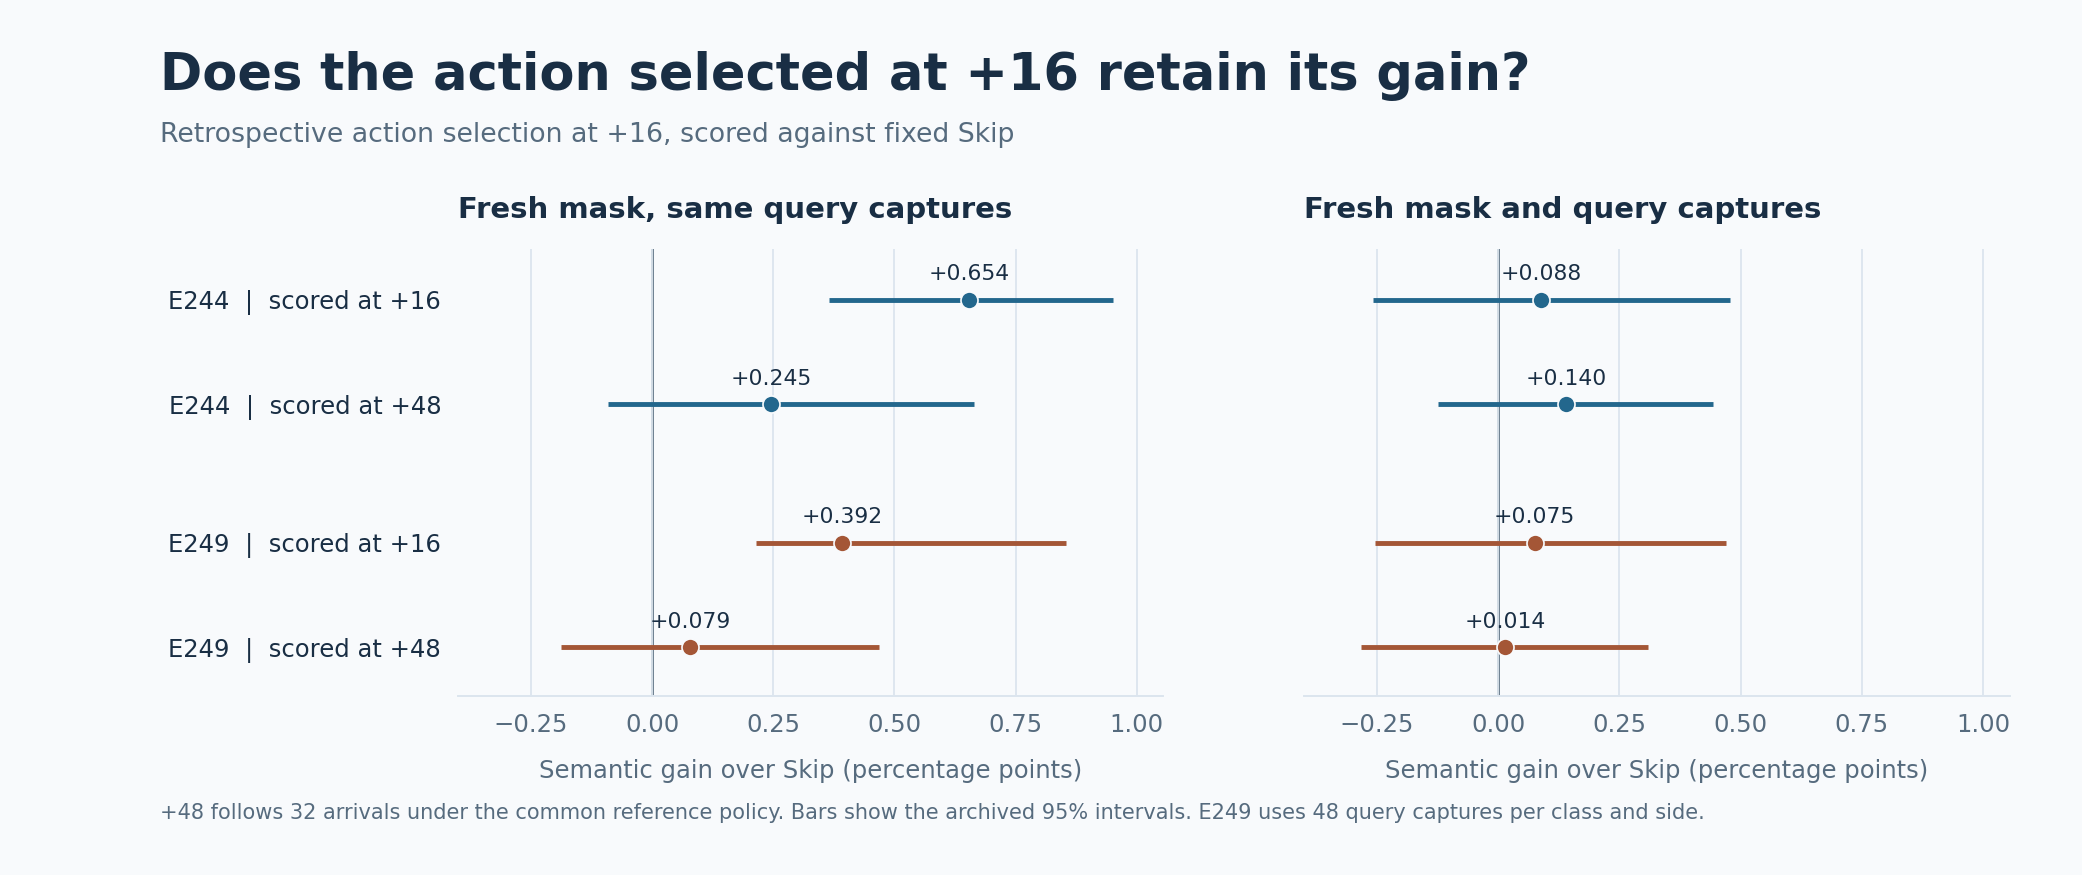

## Archived estimates

The table applies the persistence check to the published rounded intervals. A positive
lower bound would establish a gain in this comparison. Both +16 → +48 estimates also fall
below the studies' +0.25 pp effect benchmark.

In [1]:
import json
from IPython.display import Markdown, display

# Rounded point estimates and published 95% intervals from E244 and E249.
rows = json.loads('[\n  {\n    "study": "E244",\n    "evaluation": 16,\n    "axis": "mask",\n    "mean": 0.654,\n    "lower": 0.366,\n    "upper": 0.951\n  },\n  {\n    "study": "E244",\n    "evaluation": 16,\n    "axis": "panel",\n    "mean": 0.093,\n    "lower": -0.266,\n    "upper": 0.499\n  },\n  {\n    "study": "E244",\n    "evaluation": 16,\n    "axis": "both",\n    "mean": 0.088,\n    "lower": -0.258,\n    "upper": 0.479\n  },\n  {\n    "study": "E244",\n    "evaluation": 48,\n    "axis": "mask",\n    "mean": 0.245,\n    "lower": -0.09,\n    "upper": 0.665\n  },\n  {\n    "study": "E244",\n    "evaluation": 48,\n    "axis": "panel",\n    "mean": 0.144,\n    "lower": -0.127,\n    "upper": 0.451\n  },\n  {\n    "study": "E244",\n    "evaluation": 48,\n    "axis": "both",\n    "mean": 0.14,\n    "lower": -0.124,\n    "upper": 0.444\n  },\n  {\n    "study": "E249",\n    "evaluation": 16,\n    "axis": "mask",\n    "mean": 0.392,\n    "lower": 0.215,\n    "upper": 0.854\n  },\n  {\n    "study": "E249",\n    "evaluation": 16,\n    "axis": "panel",\n    "mean": 0.068,\n    "lower": -0.258,\n    "upper": 0.467\n  },\n  {\n    "study": "E249",\n    "evaluation": 16,\n    "axis": "both",\n    "mean": 0.075,\n    "lower": -0.254,\n    "upper": 0.47\n  },\n  {\n    "study": "E249",\n    "evaluation": 48,\n    "axis": "mask",\n    "mean": 0.079,\n    "lower": -0.188,\n    "upper": 0.469\n  },\n  {\n    "study": "E249",\n    "evaluation": 48,\n    "axis": "panel",\n    "mean": 0.015,\n    "lower": -0.294,\n    "upper": 0.323\n  },\n  {\n    "study": "E249",\n    "evaluation": 48,\n    "axis": "both",\n    "mean": 0.014,\n    "lower": -0.283,\n    "upper": 0.309\n  }\n]')

axes = {'mask': 'Fresh mask', 'panel': 'Fresh query captures', 'both': 'Fresh mask and query captures'}
lines = ['| Study | Scored at | Evaluation change | Gain over Skip | 95% interval |',
         '| --- | --- | --- | ---: | ---: |']
for row in rows:
    lines.append(f"| {row['study']} | +{row['evaluation']} | {axes[row['axis']]} "
                 f"| {row['mean']:+.3f} pp | [{row['lower']:+.3f}, {row['upper']:+.3f}] pp |")
display(Markdown('\n'.join(lines)))

gate = [r for r in rows if r['evaluation'] == 48 and r['axis'] == 'both']
assert {row['study'] for row in gate} == {'E244', 'E249'}
assert all(row['lower'] <= 0 for row in gate)
for row in gate:
    print(f"{row['study']} +16 to +48: {row['mean']:+.3f} pp. "
          "The published interval includes zero.")
print('Persistence gate: missed.')

| Study | Scored at | Evaluation change | Gain over Skip | 95% interval |
| --- | --- | --- | ---: | ---: |
| E244 | +16 | Fresh mask | +0.654 pp | [+0.366, +0.951] pp |
| E244 | +16 | Fresh query captures | +0.093 pp | [-0.266, +0.499] pp |
| E244 | +16 | Fresh mask and query captures | +0.088 pp | [-0.258, +0.479] pp |
| E244 | +48 | Fresh mask | +0.245 pp | [-0.090, +0.665] pp |
| E244 | +48 | Fresh query captures | +0.144 pp | [-0.127, +0.451] pp |
| E244 | +48 | Fresh mask and query captures | +0.140 pp | [-0.124, +0.444] pp |
| E249 | +16 | Fresh mask | +0.392 pp | [+0.215, +0.854] pp |
| E249 | +16 | Fresh query captures | +0.068 pp | [-0.258, +0.467] pp |
| E249 | +16 | Fresh mask and query captures | +0.075 pp | [-0.254, +0.470] pp |
| E249 | +48 | Fresh mask | +0.079 pp | [-0.188, +0.469] pp |
| E249 | +48 | Fresh query captures | +0.015 pp | [-0.294, +0.323] pp |
| E249 | +48 | Fresh mask and query captures | +0.014 pp | [-0.283, +0.309] pp |

E244 +16 to +48: +0.140 pp. The published interval includes zero.
E249 +16 to +48: +0.014 pp. The published interval includes zero.
Persistence gate: missed.


## Offline comparison once the gate clears

Use the same causal pre-action features and action set for every predictor. Fit on
development walks with paired counterfactual branches, then score all predictions on the
same independently sampled walks and augmentation draws.

| Predictor | Training target | Score used at decision time |
| --- | --- | --- |
| Immediate proxy | +1 action advantage | Predicted +1 advantage |
| Direct delayed | +16 action advantage | Predicted +16 advantage |
| Immediate + persistence | +1 advantage and the shift from +1 to +16, fit with separate heads | Sum of the two predicted terms |

For the persistence head, the target is the measured +16 advantage minus the measured
+1 advantage of the same action against the same reference. Both terms are forecast
before choosing the action.

Report +16 prediction error, pairwise action-ranking accuracy, objective regret and
independent semantic transfer. Compute regret against the measured best action on each
held-out origin and draw. For each predictor pair, subtract regrets **within that same
origin and draw** and report a 95% interval for the mean difference. Resample independent
MAE seeds and held-out walks, keeping paired actions and mask draws together. Predictor
initializations are fit replicates within a learner seed. Semantic uncertainty also
resamples query captures when the per-query receipts are available.

## Sources

[E244 · Durable MAE action value](E244.ipynb)  
[E249 · Larger matched query panels](E249.ipynb)